<a href="https://colab.research.google.com/github/analyst-suroj/ML-Projects/blob/main/Medical_Insurance_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score


In [5]:
df = pd.read_csv('/insurance.csv')



In [6]:
df.head()
df.dtypes

,0
age,int64
sex,object
bmi,float64
children,int64
smoker,object
region,object
charges,float64


In [7]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [8]:
df.groupby('smoker')['charges'].mean()

,charges
smoker,
no,8434.268298
yes,32050.231832


In [9]:
df['age'].corr(df['charges'])

np.float64(0.29900819333064754)

In [10]:
df['bmi'].corr(df['charges'])


np.float64(0.19834096883362895)

In [11]:
df['charges'].describe()

,charges
count,1338.000000
mean,13270.422265
std,12110.011237
min,1121.873900
25%,4740.287150
50%,9382.033000
75%,16639.912515
max,63770.428010


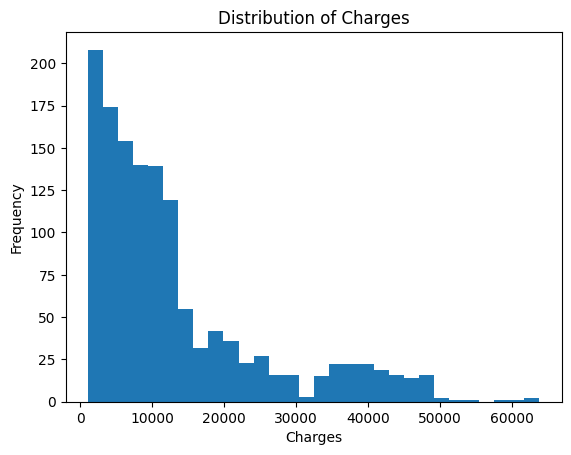

In [12]:
plt.hist(df['charges'], bins=30)
plt.xlabel('Charges')
plt.ylabel('Frequency')
plt.title('Distribution of Charges')
plt.show()

In [13]:
df = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], dtype=int)

In [14]:
X = df.drop(columns=['charges'])
y = df['charges']

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [16]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [17]:
predict = model.predict(X_test)
mae = mean_absolute_error(y_test, predict)
r2 = r2_score(y_test, predict)
print(f'Mean Absolute Error: {mae}')
print(f'R-squared: {r2}')
print(predict)


Mean Absolute Error: 4181.194473753647
R-squared: 0.7835929767120722
[ 8969.55027444  7068.74744287 36858.41091155  9454.67850053
 26973.17345656 10864.11316424   170.28084137 16903.45028662
  1092.43093614 11218.34318352 28101.68455267  9377.73460205
  5263.0595179  38416.04221107 40255.82339284 37098.25353123
 15240.39392306 35912.88264434  9112.52398703 31461.92108909
  3847.68845883 10130.12001517  2370.54189389  7140.21550828
 11301.76782638 12961.65366224 14509.47251876  6159.8976107
  9963.85857263  2177.85718217  9115.93673493 13073.68932159
  4561.82376202  3408.20756033  4459.81359745 13032.06505076
  1979.99357292  8813.28303302 33271.29124448 32585.51583927
  3908.76090964  4326.10774721 14142.81326533 11423.45494846
  8774.13955311 12097.28051001  5281.57353499  3150.5596042
 35494.46461214  9150.1124786  15836.84575621  2343.57470069
 12364.78414194  1482.29488266 13389.06105161 12573.57395972
  4341.83680558 32165.33688042 13321.3360032  12896.82071102
 14167.99421483 10

In [18]:
comparison = pd.DataFrame({'Actual Charges': y_test, 'Predicted Charges': predict})
print(comparison)

      Actual Charges  Predicted Charges
764       9095.06825        8969.550274
887       5272.17580        7068.747443
890      29330.98315       36858.410912
1293      9301.89355        9454.678501
259      33750.29180       26973.173457
...              ...                ...
109      47055.53210       39061.500932
575      12222.89830       11761.499198
535       6067.12675        7687.563632
543      63770.42801       40920.291512
846       9872.70100       12318.586653

[268 rows x 2 columns]


In [19]:

new_customer = pd.DataFrame({
    'age': [25],
    'bmi': [28.5],
    'children': [0],
    'sex_male': [1],
    'smoker_yes': [1],
    'region_northeast': [0],
    'region_northwest': [0],
    'region_southeast': [1],
    'region_southwest': [0]
})

In [20]:

new_customer_aligned = new_customer.reindex(columns=X_train.columns, fill_value=0)

prediction = model.predict(new_customer_aligned)
print("Predicted Insurance Charges:", prediction[0])

Predicted Insurance Charges: 27074.984193548982
